In [ ]:
# ============================================================
# Cell 1: Install Requirements
# ============================================================
!pip -q install open-clip-torch albumentations opencv-python-headless scikit-learn seaborn tqdm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.8 MB/s eta 0:00:00


In [ ]:
# ============================================================
# Cell 2: Mount Drive & Set Direct Google Drive Paths
# ============================================================
import os
from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Project Directory in Google Drive
PROJECT_DIR = Path("/content/drive/MyDrive/AI_Image_Detection")
PROCESSED_DATASET = PROJECT_DIR / "processed_dataset_final"

if not PROCESSED_DATASET.exists():
    raise FileNotFoundError(f"Processed dataset not found in Drive at: {PROCESSED_DATASET}")

# Direct Google Drive Dataset Paths
TEST_DIR = PROCESSED_DATASET / "test"
VAL_DIR = PROCESSED_DATASET / "val"

TEST_MANIFEST = PROCESSED_DATASET / "test_manifest.csv"
VAL_MANIFEST = PROCESSED_DATASET / "val_manifest.csv"

# Directories for Model Checkpoints and Results
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints_final"
RESULTS_DIR    = PROJECT_DIR / "results_final"
REPORT_DIR     = PROJECT_DIR / "reports_final"

for directory in [RESULTS_DIR, REPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Verify Test Manifest
if not TEST_MANIFEST.exists():
    raise FileNotFoundError(f"Missing test manifest at: {TEST_MANIFEST}")

print("=" * 70)
print("DIRECT GOOGLE DRIVE PATHS INITIALIZED")
print("=" * 70)
print(f"Project Dir   : {PROJECT_DIR}")
print(f"Test Dir      : {TEST_DIR}")
print(f"Test Manifest : {TEST_MANIFEST}")
print(f"Checkpoints   : {CHECKPOINT_DIR}")
print("=" * 70)


Mounted at /content/drive
DIRECT GOOGLE DRIVE PATHS INITIALIZED
Project Dir   : /content/drive/MyDrive/AI_Image_Detection
Test Dir      : /content/drive/MyDrive/AI_Image_Detection/processed_dataset_final/test
Test Manifest : /content/drive/MyDrive/AI_Image_Detection/processed_dataset_final/test_manifest.csv
Checkpoints   : /content/drive/MyDrive/AI_Image_Detection/checkpoints_final


In [ ]:
# ============================================================
# Cell 3: Imports & Config
# ============================================================
import csv
import json
import random
from dataclasses import dataclass

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import open_clip
import torchvision.models as models
import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report
)
from sklearn.calibration import calibration_curve
from tqdm.auto import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)

@dataclass
class EvalConfig:
    batch_size: int = 16
    num_workers: int = 2
    use_tta_flip: bool = True
    hidden1: int = 512
    hidden2: int = 256
    feature_dropout: float = 0.1
    fc_dropout: float = 0.4

cfg = EvalConfig()
print(f"Evaluation running on device: {DEVICE}")


Evaluation running on device: cuda


In [ ]:
# ============================================================
# Cell 4: Dataset Class (Direct Reading from Drive)
# ============================================================
class FaceAuthenticityDataset(Dataset):
    def __init__(self, manifest: list, image_dir: Path):
        self.manifest = manifest
        self.image_dir = image_dir

        self.transform = A.Compose([
            A.Resize(384, 384),
            ToTensorV2()
        ])

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        row = self.manifest[idx]

        # Flexibly resolve path directly from Drive manifest
        raw_path = row.get('path', row.get('filename', ''))
        img_path = Path(raw_path)

        if not img_path.exists():
            filename = img_path.name
            label_folder = str(row.get('label', '')).lower()
            candidate = self.image_dir / label_folder / filename
            if candidate.exists():
                img_path = candidate
            else:
                img_path = self.image_dir / filename

        # Read image directly from Drive path
        image = cv2.imread(str(img_path))
        if image is None:
            image = np.zeros((384, 384, 3), dtype=np.uint8)
        else:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        augmented = self.transform(image=image)
        image_tensor = augmented['image'].float() / 255.0

        label_str = str(row.get('label', '0')).lower()
        label = 1.0 if label_str in ['ai', 'fake', '1'] else 0.0

        source = str(row.get('source', 'unknown'))
        return image_tensor, torch.tensor(label, dtype=torch.float32), source


In [ ]:
# ============================================================
# Cell 5: Model Architecture Definition
# ============================================================
class FrozenFaceBackbone(nn.Module):
    embedding_dim = 512
    def __init__(self):
        super().__init__()
        self.model = models.resnet50(weights=None)
        self.model.fc = nn.Linear(self.model.fc.in_features, self.embedding_dim)
        self.model.eval()
        for p in self.model.parameters(): p.requires_grad_(False)

        self.register_buffer("mean", torch.tensor([0.5, 0.5, 0.5]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.5, 0.5, 0.5]).view(1, 3, 1, 1))

    def forward(self, x01):
        x = (x01 - self.mean) / self.std
        emb = self.model(x)
        return F.normalize(emb, dim=1)


class FrozenCLIPBackbone(nn.Module):
    embedding_dim = 768
    def __init__(self):
        super().__init__()
        model, _, _ = open_clip.create_model_and_transforms('ViT-L-14', pretrained='openai')
        self.model = model.visual
        self.model.eval()
        for p in self.model.parameters(): p.requires_grad_(False)

        clip_mean = [0.48145466, 0.4578275, 0.40821073]
        clip_std = [0.26862954, 0.26130258, 0.27577711]
        self.register_buffer("mean", torch.tensor(clip_mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(clip_std).view(1, 3, 1, 1))

    def forward(self, x01):
        x = (x01 - self.mean) / self.std
        feat = self.model(x)
        return F.normalize(feat.float(), dim=1)


class FusionHead(nn.Module):
    def __init__(self, face_dim, clip_dim, hidden1, hidden2, feat_drop, fc_drop):
        super().__init__()
        self.input_norm = nn.LayerNorm(face_dim + clip_dim)
        self.feature_dropout = nn.Dropout(feat_drop)
        self.net = nn.Sequential(
            nn.Linear(face_dim + clip_dim, hidden1),
            nn.BatchNorm1d(hidden1),
            nn.GELU(),
            nn.Dropout(fc_drop),
            nn.Linear(hidden1, hidden2),
            nn.BatchNorm1d(hidden2),
            nn.GELU(),
            nn.Dropout(fc_drop),
            nn.Linear(hidden2, 1),
        )

    def forward(self, face_emb, clip_emb):
        x = torch.cat([face_emb, clip_emb], dim=1)
        return self.net(self.feature_dropout(self.input_norm(x))).squeeze(1)


class FusionModel(nn.Module):
    def __init__(self, cfg: EvalConfig):
        super().__init__()
        self.face_backbone = FrozenFaceBackbone()
        self.clip_backbone = FrozenCLIPBackbone()
        self.head = FusionHead(
            self.face_backbone.embedding_dim,
            self.clip_backbone.embedding_dim,
            cfg.hidden1, cfg.hidden2, cfg.feature_dropout, cfg.fc_dropout
        )

    def forward(self, x_384):
        clip_input = F.interpolate(x_384, size=(224, 224), mode='bicubic', antialias=True)
        crop_size = int(x_384.shape[-1] * 0.8)
        start = (x_384.shape[-1] - crop_size) // 2
        face_crop = x_384[:, :, start:start + crop_size, start:start + crop_size]
        face_input = F.interpolate(face_crop, size=(112, 112), mode='bicubic', antialias=True)
        return self.head(self.face_backbone(face_input), self.clip_backbone(clip_input))


class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.temperature = nn.Parameter(torch.ones(1) * 1.5)

    def forward(self, logits):
        return logits / self.temperature

    def fit(self, logits, labels):
        nll_criterion = nn.BCEWithLogitsLoss()
        optimizer = torch.optim.LBFGS([self.temperature], lr=0.01, max_iter=50)
        def eval():
            optimizer.zero_grad()
            loss = nll_criterion(self.forward(logits), labels)
            loss.backward()
            return loss
        optimizer.step(eval)
        return self.temperature.item()


In [ ]:
# ============================================================
# Cell 6: Inference Engine
# ============================================================
@torch.no_grad()
def collect_predictions(model, loader, use_tta_flip=True):
    model.eval()
    all_logits, all_labels, all_sources = [], [], []

    for images, labels, sources in tqdm(loader, desc="Running Inference"):
        images = images.to(DEVICE)
        logits = model(images)

        if use_tta_flip:
            logits_flipped = model(torch.flip(images, dims=[-1]))
            logits = (logits + logits_flipped) / 2.0

        all_logits.append(logits.cpu())
        all_labels.append(labels)
        all_sources.extend(sources)

    return torch.cat(all_logits), torch.cat(all_labels), np.array(all_sources)


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Loading weights from: /content/drive/MyDrive/AI_Image_Detection/checkpoints_final/best_final_model.pt

--- Step 1: Probability Calibration on Validation Set ---


Running Inference:   0%|          | 0/179 [00:00<?, ?it/s]

Calibrated Optimal Temperature: 0.7712

--- Step 2: Testing Model on Unseen Test Set ---


Running Inference:   0%|          | 0/180 [00:00<?, ?it/s]


GLOBAL UNSEEN TEST SET RESULTS
              precision    recall  f1-score   support

        Real     0.9956    0.9931    0.9944      1597
          AI     0.9914    0.9945    0.9929      1274

    accuracy                         0.9937      2871
   macro avg     0.9935    0.9938    0.9937      2871
weighted avg     0.9937    0.9937    0.9937      2871

Test Accuracy : 99.37%
Test ROC-AUC  : 0.9999
Test F1-Score : 0.9929

PER-SOURCE BREAKDOWN ANALYSIS
Source Dataset            | Label  | Count   | Accuracy   | F1-Score  
--------------------------------------------------------------------------------
anime                     | AI     | 100     | 100.00%   |   1.0000
deepfake                  | AI     | 300     | 100.00%   |   1.0000
ffhq                      | Real   | 1000    |  99.00%   |   0.0000
finetune                  | AI     | 11      | 100.00%   |   1.0000
lfw                       | Real   | 397     | 100.00%   |   0.0000
nano_banana               | AI     | 91      |  9

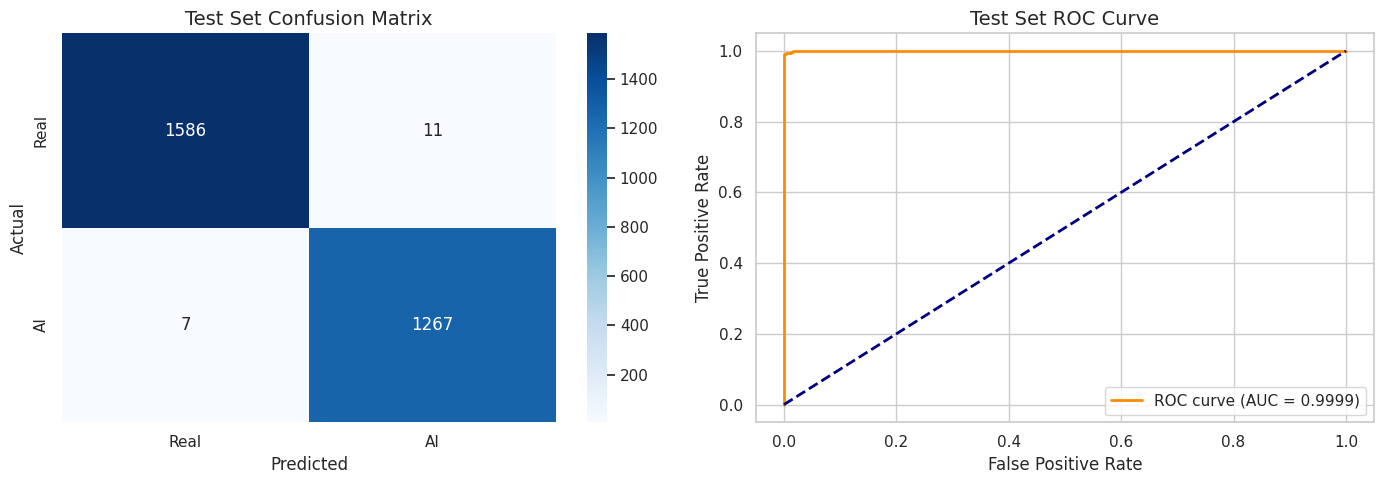


Artifacts saved:
- Report CSV : /content/drive/MyDrive/AI_Image_Detection/reports_final/test_per_source_analysis.csv
- Charts PNG : /content/drive/MyDrive/AI_Image_Detection/results_final/test_evaluation_summary.png


In [ ]:
# ============================================================
# Cell 7: Full Evaluation & Report Generation
# ============================================================
def load_manifest(path):
    with open(path) as f: return list(csv.DictReader(f))

# 1. Load Manifests directly from Drive
val_manifest = load_manifest(VAL_MANIFEST)
test_manifest = load_manifest(TEST_MANIFEST)

val_ds = FaceAuthenticityDataset(val_manifest, VAL_DIR)
test_ds = FaceAuthenticityDataset(test_manifest, TEST_DIR)

val_loader = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers)
test_loader = DataLoader(test_ds, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers)

# 2. Load Model Weights
model = FusionModel(cfg).to(DEVICE)

# Try best model first, fallback to latest checkpoint
model_weight_path = CHECKPOINT_DIR / "best_final_model.pt"
if not model_weight_path.exists():
    model_weight_path = CHECKPOINT_DIR / "latest_training_checkpoint.pt"

if not model_weight_path.exists():
    raise FileNotFoundError(f"No checkpoint found in {CHECKPOINT_DIR}")

print(f"Loading weights from: {model_weight_path}")
checkpoint = torch.load(model_weight_path, map_location=DEVICE)

if "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()

# 3. Step 1: Calibrate Temperature on Validation Set (Prevents Data Leakage)
print("\n--- Step 1: Probability Calibration on Validation Set ---")
val_logits, val_labels, _ = collect_predictions(model, val_loader, use_tta_flip=cfg.use_tta_flip)
scaler_model = TemperatureScaler().to(DEVICE)
optimal_temp = scaler_model.fit(val_logits.to(DEVICE), val_labels.float().to(DEVICE))
print(f"Calibrated Optimal Temperature: {optimal_temp:.4f}")

# 4. Step 2: Evaluate on Unseen Test Set
print("\n--- Step 2: Testing Model on Unseen Test Set ---")
test_logits, test_labels, test_sources = collect_predictions(model, test_loader, use_tta_flip=cfg.use_tta_flip)

# Scale Test Probabilities
test_probs = torch.sigmoid(test_logits / optimal_temp).numpy()
y_true = test_labels.numpy()
preds = (test_probs >= 0.5).astype(int)

# 5. Global Metrics
print("\n" + "=" * 70)
print("GLOBAL UNSEEN TEST SET RESULTS")
print("=" * 70)
print(classification_report(y_true, preds, target_names=['Real', 'AI'], digits=4))

overall_auc = roc_auc_score(y_true, test_probs)
overall_acc = accuracy_score(y_true, preds)
overall_f1 = f1_score(y_true, preds)

print(f"Test Accuracy : {overall_acc * 100:.2f}%")
print(f"Test ROC-AUC  : {overall_auc:.4f}")
print(f"Test F1-Score : {overall_f1:.4f}")

# 6. Per-Source Detailed Analysis
print("\n" + "=" * 80)
print("PER-SOURCE BREAKDOWN ANALYSIS")
print("=" * 80)
print(f"{'Source Dataset':<25} | {'Label':<6} | {'Count':<7} | {'Accuracy':<10} | {'F1-Score':<10}")
print("-" * 80)

source_metrics = []
unique_sources = np.unique(test_sources)

for source in unique_sources:
    mask = (test_sources == source)
    s_true = y_true[mask]
    s_preds = preds[mask]
    s_probs = test_probs[mask]

    s_count = len(s_true)
    s_acc = accuracy_score(s_true, s_preds)
    s_f1 = f1_score(s_true, s_preds, zero_division=0)
    s_label = "AI" if s_true[0] == 1 else "Real"

    print(f"{source:<25} | {s_label:<6} | {s_count:<7} | {s_acc*100:>6.2f}%   | {s_f1:>8.4f}")

    source_metrics.append({
        "Source": source,
        "Class": s_label,
        "Count": s_count,
        "Accuracy": s_acc,
        "F1_Score": s_f1
    })

# Save CSV Report
df_report = pd.DataFrame(source_metrics)
df_report.to_csv(REPORT_DIR / "test_per_source_analysis.csv", index=False)

# 7. Generate & Save Figures
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_true, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Real', 'AI'], yticklabels=['Real', 'AI'], ax=axes[0])
axes[0].set_title('Test Set Confusion Matrix', fontsize=14)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC Curve
fpr, tpr, _ = roc_curve(y_true, test_probs)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {overall_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Test Set ROC Curve', fontsize=14)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_evaluation_summary.png", dpi=300)
plt.show()

print(f"\nArtifacts saved:")
print(f"- Report CSV : {REPORT_DIR / 'test_per_source_analysis.csv'}")
print(f"- Charts PNG : {RESULTS_DIR / 'test_evaluation_summary.png'}")


In [ ]:
# 1. Imports & Device
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import open_clip

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# 2. Paste the Architecture Classes Here
# (FrozenFaceBackbone, FrozenCLIPBackbone, FusionHead, FusionModel)

# 3. Load the Weights
model = FusionModel(cfg=type('cfg', (), {'hidden1': 512, 'hidden2': 256, 'feature_dropout': 0.1, 'fc_dropout': 0.4})())
model.to(DEVICE)

checkpoint_path = "/content/drive/MyDrive/AI_Image_Detection/checkpoints_final/best_final_model.pt"
checkpoint = torch.load(checkpoint_path, map_location=DEVICE)

if "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()
print("Model loaded and ready for inference!")


In [ ]:
# ============================================================
# Interactive Inference: Real vs. AI-Generated (Final Fixed Version)
# ============================================================
!pip install -q insightface onnxruntime

import os
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from insightface.app import FaceAnalysis
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Ensure DEVICE is defined if running in a fresh environment
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("\nInitializing RetinaFace Detector (this may take a few seconds)...")
# 1. Initialize the RetinaFace Detector
detector = FaceAnalysis(
    name="buffalo_l",
    allowed_modules=["detection"],
    providers=["CUDAExecutionProvider"] if DEVICE == "cuda" else ["CPUExecutionProvider"],
)
detector.prepare(ctx_id=0 if DEVICE == "cuda" else -1, det_size=(640, 640))

# 2. Pipeline Constants & Calibrated Temperature
OPTIMAL_TEMP = 0.7712
OFFLINE_MARGIN = 1.4
MASTER_SIZE = 384
FALLBACK_CENTER_CROP_FRAC = 0.8

# 3. Define Cropping Functions (Matching Training Preprocessing)
def _expand_and_square_box(box, margin):
    x1, y1, x2, y2 = box
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    side = max(x2 - x1, y2 - y1) * margin
    half = side / 2
    return cx - half, cy - half, cx + half, cy + half

def _crop_with_reflect_pad(image, box):
    img_w, img_h = image.size
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    pad_left = max(0, -x1)
    pad_top = max(0, -y1)
    pad_right = max(0, x2 - img_w)
    pad_bottom = max(0, y2 - img_h)

    if any([pad_left, pad_top, pad_right, pad_bottom]):
        arr = np.array(image)
        arr = np.pad(arr, ((pad_top, pad_bottom), (pad_left, pad_right), (0, 0)), mode="reflect")
        image = Image.fromarray(arr)
        x1, y1, x2, y2 = x1 + pad_left, y1 + pad_top, x2 + pad_left, y2 + pad_top

    return image.crop((x1, y1, x2, y2))

def get_face_crop(image_pil):
    bgr = np.array(image_pil)[:, :, ::-1]
    faces = detector.get(bgr)

    if not faces:
        print("[Warning] No face detected by RetinaFace. Falling back to center crop.")
        img_w, img_h = image_pil.size
        side = min(img_w, img_h) * FALLBACK_CENTER_CROP_FRAC
        cx, cy = img_w / 2, img_h / 2
        inner_box = (cx - side / 2, cy - side / 2, cx + side / 2, cy + side / 2)
    else:
        best = max(faces, key=lambda f: f.det_score)
        x1, y1, x2, y2 = best.bbox
        inner_box = (float(x1), float(y1), float(x2), float(y2))

    box = _expand_and_square_box(inner_box, OFFLINE_MARGIN)
    cropped = _crop_with_reflect_pad(image_pil, box)
    return cropped.resize((MASTER_SIZE, MASTER_SIZE), Image.Resampling.LANCZOS)

# 4. Corrected Inference Transform (ToTensorV2 only, single /255 scaling below)
infer_transform = A.Compose([
    ToTensorV2(),
])

# 5. Prediction Function
@torch.no_grad()
def predict_image(image_path, model):
    model.eval()

    # Load and process image
    raw_img = Image.open(image_path).convert("RGB")
    face_crop_img = get_face_crop(raw_img)

    # Convert for Albumentations and apply single division to [0, 1] range
    img_array = np.array(face_crop_img)
    tensor = infer_transform(image=img_array)["image"].float() / 255.0
    tensor = tensor.unsqueeze(0).to(DEVICE) # Shape: (1, 3, 384, 384)

    # Forward Pass with Test-Time Augmentation (TTA)
    logits_normal = model(tensor)
    logits_flipped = model(torch.flip(tensor, dims=[-1]))
    logits = (logits_normal + logits_flipped) / 2.0

    # Apply Calibrated Temperature Scaling and Sigmoid
    prob = torch.sigmoid(logits / OPTIMAL_TEMP).item()

    label = "AI-Generated" if prob >= 0.5 else "Real Photo"
    confidence = prob if prob >= 0.5 else (1.0 - prob)

    # Display Results
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(raw_img)
    axes[0].set_title("Original Upload")
    axes[0].axis("off")

    axes[1].imshow(face_crop_img)
    axes[1].set_title(f"Prediction: {label}\nConfidence: {confidence * 100:.2f}%")
    axes[1].axis("off")

    # Color code the result box
    color = "darkred" if label == "AI-Generated" else "darkgreen"
    for spine in axes[1].spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(4)

    plt.tight_layout()
    plt.show()

# 6. Interactive Upload Loop
print("\n" + "=" * 50)
print("READY FOR INFERENCE")
print("=" * 50)

uploaded = files.upload()

for filename in uploaded.keys():
    print(f"\nProcessing {filename}...")
    predict_image(filename, model)
    os.remove(filename)


In [ ]:
# 5. Prediction Function
@torch.no_grad()
def predict_image(image_path, model):
    model.eval()

    # Load and process image
    raw_img = Image.open(image_path).convert("RGB")
    face_crop_img = get_face_crop(raw_img)

    # Convert for Albumentations and apply single division to [0, 1] range
    img_array = np.array(face_crop_img)
    tensor = infer_transform(image=img_array)["image"].float() / 255.0
    tensor = tensor.unsqueeze(0).to(DEVICE) # Shape: (1, 3, 384, 384)

    # Forward Pass with Test-Time Augmentation (TTA)
    logits_normal = model(tensor)
    logits_flipped = model(torch.flip(tensor, dims=[-1]))
    logits = (logits_normal + logits_flipped) / 2.0

    # Apply Calibrated Temperature Scaling and Sigmoid
    prob = torch.sigmoid(logits / OPTIMAL_TEMP).item()

    label = "AI-Generated" if prob >= 0.5 else "Real Photo"
    confidence = prob if prob >= 0.5 else (1.0 - prob)

    # Display Results
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(raw_img)
    axes[0].set_title("Original Upload")
    axes[0].axis("off")

    axes[1].imshow(face_crop_img)
    axes[1].set_title(f"Prediction: {label}\nConfidence: {confidence * 100:.2f}%")
    axes[1].axis("off")

    # Color code the result box
    color = "darkred" if label == "AI-Generated" else "darkgreen"
    for spine in axes[1].spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(4)

    plt.tight_layout()
    plt.show()

# 6. Interactive Upload Loop
print("\n" + "=" * 50)
print("READY FOR INFERENCE")
print("=" * 50)

uploaded = files.upload()

for filename in uploaded.keys():
    print(f"\nProcessing {filename}...")
    predict_image(filename, model)
    os.remove(filename)
